In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CHEMIN = "../data/raw/"

train = pd.read_csv(CHEMIN + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN + "telcopeople_test.csv")
dictionnaire = pd.read_csv(CHEMIN + "telcopeople_data_dictionary.csv")

print("Train :", train.shape)
print("Test :", test.shape)
print("Dictionnaire :", dictionnaire.shape)

Train : (5444, 42)
Test : (1507, 41)
Dictionnaire : (85, 3)


In [2]:
print("Colonnes uniquement dans train :", set(train.columns) - set(test.columns))
print("\nListe des colonnes :")
print(train.columns.tolist())

Colonnes uniquement dans train : {'target'}

Liste des colonnes :
['id', 'date_reference', 'genre', 'date_naissance', 'ville_affectation', 'departement', 'poste', 'niveau_etude', 'contrat', 'grade', 'date_embauche', 'date_derniere_promotion', 'salaire_mensuel', 'salaire_12m_avant', 'reference_salaire_grade', 'performance_actuelle', 'performance_precedente', 'engagement_actuel', 'engagement_precedent', 'date_derniere_absence', 'jours_abs_m1', 'jours_abs_m2', 'jours_abs_m3', 'jours_abs_m4', 'jours_abs_m5', 'jours_abs_m6', 'abs_non_just_m1', 'abs_non_just_m2', 'abs_non_just_m3', 'abs_non_just_m4', 'abs_non_just_m5', 'abs_non_just_m6', 'nb_abs_m1', 'nb_abs_m2', 'nb_abs_m3', 'nb_abs_m4', 'nb_abs_m5', 'nb_abs_m6', 'taille_departement', 'code_site', 'source_sirh', 'target']


In [3]:
audit = pd.DataFrame({
    "type": train.dtypes,
    "valeurs_manquantes": train.isna().sum(),
    "taux_manquant_pct": (train.isna().mean() * 100).round(2),
    "valeurs_uniques": train.nunique()
})

audit.sort_values("taux_manquant_pct", ascending=False)

,type,valeurs_manquantes,taux_manquant_pct,valeurs_uniques
date_derniere_promotion,str,4494,82.55,142
date_derniere_absence,str,3059,56.19,640
engagement_precedent,float64,1797,33.01,3551
performance_precedente,float64,1608,29.54,510
salaire_12m_avant,float64,1460,26.82,1244
performance_actuelle,float64,706,12.97,302
engagement_actuel,float64,568,10.43,333
reference_salaire_grade,float64,65,1.19,1353
niveau_etude,str,65,1.19,8
genre,str,44,0.81,2


In [4]:
effectifs = train["target"].value_counts()
pourcentages = train["target"].value_counts(normalize=True).mul(100).round(2)

print("Effectifs :")
print(effectifs)

print("\nPourcentages :")
print(pourcentages)

Effectifs :
target
0    4892
1     552
Name: count, dtype: int64

Pourcentages :
target
0    89.86
1    10.14
Name: proportion, dtype: float64


In [5]:
print("Doublons complets :", train.duplicated().sum())
print("ID dupliqués :", train["id"].duplicated().sum())
print("ID manquants :", train["id"].isna().sum())

Doublons complets : 0
ID dupliqués : 0
ID manquants : 0


In [6]:
colonnes_categorielles = train.select_dtypes(include="object").columns

for colonne in colonnes_categorielles:
    if train[colonne].nunique() <= 20:
        print(f"\n--- {colonne} ---")
        print(train[colonne].value_counts(dropna=False))


--- date_reference ---
date_reference
2024-06-30    1314
2023-12-31    1189
2023-06-30    1083
2022-12-31     985
2022-06-30     873
Name: count, dtype: int64

--- genre ---
genre
M      2854
F      2546
NaN      44
Name: count, dtype: int64


C:\Users\DELL\AppData\Local\Temp\ipykernel_10500\1325097681.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colonnes_categorielles = train.select_dtypes(include="object").columns



--- ville_affectation ---
ville_affectation
Abidjan           3852
Bouaké             474
Yamoussoukro       436
San-Pédro          324
Korhogo            260
 Abidjan            37
ABIDJAN             30
BOUAKÉ               8
 Bouaké              6
SAN-PÉDRO            5
KORHOGO              4
YAMOUSSOUKRO         3
 Yamoussoukro        2
 Korhogo             2
 San-Pédro           1
Name: count, dtype: int64

--- departement ---
departement
DEP04     1366
DEP02     1082
DEP03     1042
DEP08      408
DEP05      364
DEP07      360
DEP10      248
DEP06      245
DEP09      213
DEP01       51
NaN         33
DEPT04      13
DEPT03       5
DEPT02       3
DEPT09       3
DEPT06       3
DEPT05       2
DEPT07       2
DEPT10       1
Name: count, dtype: int64

--- niveau_etude ---
niveau_etude
Bac+5       2072
Bac+3       2004
Bac+2       1084
Doctorat     139
NaN           65
BAC +5        34
bac+3         32
BAC 2         11
doctorat       3
Name: count, dtype: int64

--- contrat ---
contrat
C

In [7]:
colonnes_dates = [
    "date_reference",
    "date_naissance",
    "date_embauche",
    "date_derniere_promotion",
    "date_derniere_absence"
]

for colonne in colonnes_dates:
    dates_converties = pd.to_datetime(train[colonne], errors="coerce")
    print(
        colonne,
        "| invalides :", dates_converties.isna().sum(),
        "| manquantes initiales :", train[colonne].isna().sum()
    )

print("\nExemples de salaires :")
print(train["salaire_mensuel"].dropna().sample(15, random_state=42).tolist())

date_reference | invalides : 0 | manquantes initiales : 0
date_naissance | invalides : 98 | manquantes initiales : 0
date_embauche | invalides : 98 | manquantes initiales : 0
date_derniere_promotion | invalides : 4508 | manquantes initiales : 4494
date_derniere_absence | invalides : 3059 | manquantes initiales : 3059

Exemples de salaires :
['1995000', '585000', '500000', '1035000', '1120000', '345000', '745000', '550000', '2475000', '475000', '965000', '395000', '1305000', '485000', '490000']


In [8]:
for colonne in [
    "date_naissance",
    "date_embauche",
    "date_derniere_promotion"
]:
    dates = pd.to_datetime(train[colonne], errors="coerce", dayfirst=True)

    valeurs_invalides = train.loc[
        train[colonne].notna() & dates.isna(),
        colonne
    ].value_counts()

    print(f"\n--- {colonne} ---")
    print(valeurs_invalides.head(15))


--- date_naissance ---
date_naissance
26/03/1991    2
24/11/1982    1
06/05/1984    1
13/04/1992    1
23/06/1984    1
04/04/1989    1
12/11/1984    1
02/06/1992    1
25/10/1988    1
06/08/1992    1
27/08/1980    1
14/12/1987    1
01/04/1980    1
25/01/1982    1
22/01/1989    1
Name: count, dtype: int64

--- date_embauche ---
date_embauche
01/04/2022    4
30/11/2022    4
30/04/2021    3
31/05/2021    3
30/12/2020    3
28/02/2019    2
28/02/2022    2
29/12/2021    2
30/07/2021    2
30/09/2020    2
01/03/2021    2
30/08/2019    2
01/05/2023    2
01/06/2023    2
31/08/2023    2
Name: count, dtype: int64

--- date_derniere_promotion ---
date_derniere_promotion
31/08/2023    2
31/03/2022    1
30/03/2021    1
01/05/2020    1
28/02/2022    1
30/05/2021    1
30/06/2023    1
02/03/2023    1
31/12/2021    1
01/07/2022    1
30/12/2021    1
31/05/2021    1
01/05/2023    1
Name: count, dtype: int64


C:\Users\DELL\AppData\Local\Temp\ipykernel_10500\3135849088.py:6: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dates = pd.to_datetime(train[colonne], errors="coerce", dayfirst=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_10500\3135849088.py:6: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dates = pd.to_datetime(train[colonne], errors="coerce", dayfirst=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_10500\3135849088.py:6: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dates = pd.to_datetime(train[colonne], errors="coerce", dayfirst=True)


In [9]:
for colonne in colonnes_dates:
    dates_converties = pd.to_datetime(
        train[colonne],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

    print(
        colonne,
        "| invalides :", dates_converties.isna().sum(),
        "| manquantes initiales :", train[colonne].isna().sum()
    )

date_reference | invalides : 0 | manquantes initiales : 0
date_naissance | invalides : 0 | manquantes initiales : 0
date_embauche | invalides : 0 | manquantes initiales : 0
date_derniere_promotion | invalides : 4494 | manquantes initiales : 4494
date_derniere_absence | invalides : 3059 | manquantes initiales : 3059


In [10]:
train["salaire_mensuel_num"] = pd.to_numeric(
    train["salaire_mensuel"]
        .astype(str)
        .str.replace("FCFA", "", regex=False)
        .str.replace(" ", "", regex=False),
    errors="coerce"
)

print("Salaires invalides :", train["salaire_mensuel_num"].isna().sum())
print(train["salaire_mensuel_num"].describe())

Salaires invalides : 1
count    5.443000e+03
mean     7.797106e+05
std      6.087109e+05
min      0.000000e+00
25%      4.500000e+05
50%      6.150000e+05
75%      9.250000e+05
max      1.925000e+07
Name: salaire_mensuel_num, dtype: float64


In [11]:
train.loc[
    (train["salaire_mensuel_num"] == 0) |
    (train["salaire_mensuel_num"] > 5_000_000),
    ["id", "poste", "grade", "salaire_mensuel", "salaire_mensuel_num"]
].sort_values("salaire_mensuel_num")

,id,poste,grade,salaire_mensuel,salaire_mensuel_num
610,OBS000611,Superviseur Centre de Contacts,G2,0,0.0
902,OBS000903,Développeur,G1,0,0.0
1985,OBS001986,Analyste CX,G3,0,0.0
4964,OBS004965,Chargé Grands Comptes,G4,0,0.0
3060,OBS003061,Data Analyst,G2,0,0.0
2830,OBS002831,Analyste CX,G3,0,0.0
2463,OBS002464,Logisticien,G2,0,0.0
2149,OBS002150,Conseiller Client,G2,0,0.0
5294,OBS005295,Manager Technique,G5,0,0.0
3237,OBS003238,Conseiller Client,G1,0,0.0


In [12]:
colonnes = [
    "salaire_mensuel_num",
    "reference_salaire_grade",
    "salaire_12m_avant"
]

train[colonnes].describe(percentiles=[0.90, 0.95, 0.99]).T

,count,mean,std,min,90%,95%,99%,max
salaire_mensuel_num,5443.0,779710.637516,608710.925680,0.0,1325000.0,1784500.0,2639500.0,19250000.0
reference_salaire_grade,5379.0,767208.588957,448357.766594,305000.0,1337000.0,1668300.0,2403440.0,3238000.0
salaire_12m_avant,3984.0,751353.664659,447542.467569,241000.0,1278000.0,1694400.0,2473360.0,3221000.0


In [13]:
train["ratio_salaire_reference"] = (
    train["salaire_mensuel_num"] /
    train["reference_salaire_grade"]
)

train["ratio_salaire_reference"].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
)

count    5378.000000
mean        1.017057
std         0.482391
min         0.000000
1%          0.710317
5%          0.792519
50%         0.996377
95%         1.195417
99%         1.293980
max        11.430246
Name: ratio_salaire_reference, dtype: float64

In [14]:
for colonne in ["genre", "contrat", "grade", "departement", "source_sirh"]:
    resultat = train.groupby(colonne)["target"].agg(
        effectif="count",
        departs="sum",
        taux_depart="mean"
    )

    resultat["taux_depart"] = (resultat["taux_depart"] * 100).round(2)

    print(f"\n--- {colonne} ---")
    display(resultat.sort_values("taux_depart", ascending=False))


--- genre ---


,effectif,departs,taux_depart
genre,,,
F,2546,262,10.29
M,2854,286,10.02



--- contrat ---


,effectif,departs,taux_depart
contrat,,,
CDD,867,106,12.23
CDI,4495,445,9.90
C.D.I,70,1,1.43
cdd,12,0,0.00



--- grade ---


,effectif,departs,taux_depart
grade,,,
G4,715,78,10.91
G2,1688,182,10.78
G1,1309,138,10.54
G5,346,33,9.54
G3,1386,121,8.73



--- departement ---


,effectif,departs,taux_depart
departement,,,
DEPT03,5,2,40.00
DEP10,248,36,14.52
DEP08,408,45,11.03
DEP06,245,27,11.02
DEP04,1366,147,10.76
DEP02,1082,115,10.63
DEP03,1042,107,10.27
DEP07,360,32,8.89
DEP09,213,15,7.04



--- source_sirh ---


,effectif,departs,taux_depart
source_sirh,,,
LEGACY,309,42,13.59
HR_CORE,3945,393,9.96
PAYROLL_SYNC,1190,117,9.83


In [15]:
variables = [
    "performance_actuelle",
    "performance_precedente",
    "engagement_actuel",
    "engagement_precedent",
    "salaire_mensuel_num",
    "taille_departement"
]

train.groupby("target")[variables].mean().T.round(2)

target,0,1
performance_actuelle,3.46,3.41
performance_precedente,3.46,3.43
engagement_actuel,3.58,3.16
engagement_precedent,3.65,3.24
salaire_mensuel_num,786328.70,720952.81
taille_departement,181.16,187.90


In [16]:
train["evolution_engagement"] = (
    train["engagement_actuel"] - train["engagement_precedent"]
)

train["evolution_performance"] = (
    train["performance_actuelle"] - train["performance_precedente"]
)

train.groupby("target")[
    ["evolution_engagement", "evolution_performance"]
].mean().round(3)

,evolution_engagement,evolution_performance
target,,
0,-0.003,-0.005
1,-0.001,-0.000


In [17]:
colonnes_jours_abs = [f"jours_abs_m{i}" for i in range(1, 7)]
colonnes_abs_non_just = [f"abs_non_just_m{i}" for i in range(1, 7)]
colonnes_nb_abs = [f"nb_abs_m{i}" for i in range(1, 7)]

train["jours_abs_6m"] = train[colonnes_jours_abs].sum(axis=1)
train["abs_non_just_6m"] = train[colonnes_abs_non_just].sum(axis=1)
train["nb_abs_6m"] = train[colonnes_nb_abs].sum(axis=1)

train.groupby("target")[
    ["jours_abs_6m", "abs_non_just_6m", "nb_abs_6m"]
].mean().round(2)

,jours_abs_6m,abs_non_just_6m,nb_abs_6m
target,,,
0,1.56,0.16,0.62
1,2.07,0.23,0.84


In [18]:
date_reference = pd.to_datetime(train["date_reference"])
date_naissance = pd.to_datetime(
    train["date_naissance"], format="mixed", dayfirst=True
)
date_embauche = pd.to_datetime(
    train["date_embauche"], format="mixed", dayfirst=True
)

train["age"] = (date_reference - date_naissance).dt.days / 365.25
train["anciennete"] = (date_reference - date_embauche).dt.days / 365.25

train.groupby("target")[["age", "anciennete"]].mean().round(2)

,age,anciennete
target,,
0,36.30,2.39
1,35.95,2.49


In [19]:
date_promotion = pd.to_datetime(
    train["date_derniere_promotion"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

train["annees_depuis_promotion"] = (
    date_reference - date_promotion
).dt.days / 365.25

train["jamais_promu"] = date_promotion.isna().astype(int)

train.groupby("target")[
    ["annees_depuis_promotion", "jamais_promu"]
].mean().round(2)

,annees_depuis_promotion,jamais_promu
target,,
0,1.23,0.83
1,1.36,0.81


In [20]:
train["evolution_salaire"] = (
    train["salaire_mensuel_num"] - train["salaire_12m_avant"]
)

train["taux_evolution_salaire"] = (
    train["evolution_salaire"] / train["salaire_12m_avant"]
)

train.groupby("target")[
    ["evolution_salaire", "taux_evolution_salaire", "ratio_salaire_reference"]
].median().round(3)

,evolution_salaire,taux_evolution_salaire,ratio_salaire_reference
target,,,
0,23000.0,0.037,1.002
1,22000.0,0.038,0.937


In [21]:
analyse_engagement = train.groupby("engagement_actuel")["target"].agg(
    effectif="count",
    departs="sum",
    taux_depart="mean"
)

analyse_engagement["taux_depart"] = (
    analyse_engagement["taux_depart"] * 100
).round(2)

analyse_engagement

,effectif,departs,taux_depart
engagement_actuel,,,
1.21,1,0,0.00
1.35,1,1,100.00
1.37,1,0,0.00
1.48,1,0,0.00
1.56,1,0,0.00
...,...,...,...
4.96,6,0,0.00
4.97,5,0,0.00
4.98,4,0,0.00


In [22]:
train["niveau_engagement"] = pd.cut(
    train["engagement_actuel"],
    bins=[0, 2, 3, 4, 5],
    labels=["Très faible", "Faible", "Moyen", "Élevé"],
    include_lowest=True
)

analyse_engagement = train.groupby(
    "niveau_engagement",
    observed=False
)["target"].agg(
    effectif="count",
    departs="sum",
    taux_depart="mean"
)

analyse_engagement["taux_depart"] = (
    analyse_engagement["taux_depart"] * 100
).round(2)

analyse_engagement

,effectif,departs,taux_depart
niveau_engagement,,,
Très faible,52,17,32.69
Faible,984,188,19.11
Moyen,2649,232,8.76
Élevé,1191,49,4.11


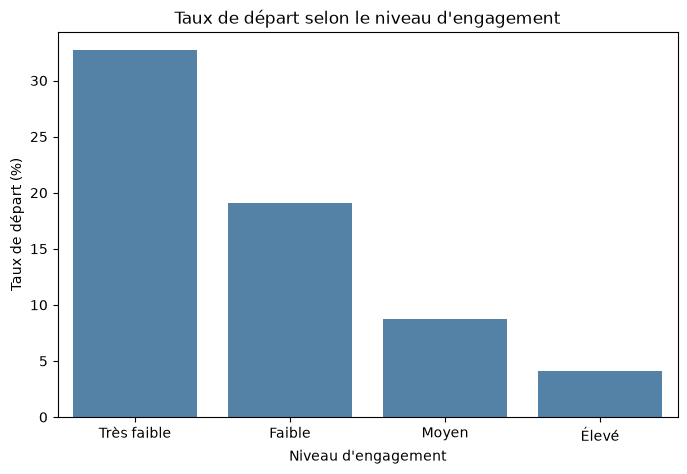

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=analyse_engagement.reset_index(),
    x="niveau_engagement",
    y="taux_depart",
    color="steelblue"
)

plt.title("Taux de départ selon le niveau d'engagement")
plt.xlabel("Niveau d'engagement")
plt.ylabel("Taux de départ (%)")
plt.show()

In [24]:
train["niveau_absence"] = pd.cut(
    train["jours_abs_6m"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=["Aucune", "1 à 2 jours", "3 à 5 jours", "Plus de 5 jours"]
)

analyse_absence = train.groupby(
    "niveau_absence",
    observed=False
)["target"].agg(
    effectif="count",
    departs="sum",
    taux_depart="mean"
)

analyse_absence["taux_depart"] = (
    analyse_absence["taux_depart"] * 100
).round(2)

analyse_absence

,effectif,departs,taux_depart
niveau_absence,,,
Aucune,3054,263,8.61
1 à 2 jours,1168,132,11.30
3 à 5 jours,744,87,11.69
Plus de 5 jours,478,70,14.64


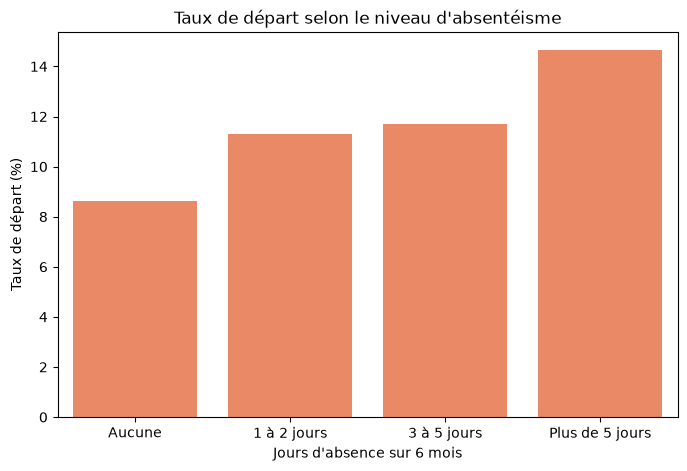

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=analyse_absence.reset_index(),
    x="niveau_absence",
    y="taux_depart",
    color="coral"
)

plt.title("Taux de départ selon le niveau d'absentéisme")
plt.xlabel("Jours d'absence sur 6 mois")
plt.ylabel("Taux de départ (%)")
plt.show()